In [13]:
import warnings

# Menyembunyikan semua DeprecationWarning di sel Jupyter
warnings.filterwarnings("ignore", category=DeprecationWarning)

Total Transaksi: 9835
Contoh 3 transaksi pertama:
- ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
- ['tropical fruit', 'yogurt', 'coffee']
- ['whole milk']

Bentuk Matrix Transaksi (One-Hot): 9835 transaksi x 171 produk unik

--- Top 5 Kombinasi Barang Paling Sering Dibeli (Support) ---
     support            itemsets  length
57  0.255516        (whole milk)       1
39  0.193493  (other vegetables)       1
43  0.183935        (rolls/buns)       1
49  0.174377              (soda)       1
58  0.139502            (yogurt)       1

--- Top 5 Association Rules Berdasarkan Nilai Lift ---
                       antecedents                     consequents   support  \
69               (root vegetables)  (other vegetables, whole milk)  0.023183   
68  (other vegetables, whole milk)               (root vegetables)  0.023183   
40                     (pip fruit)                (tropical fruit)  0.020437   
67   (root vegetables, whole milk)              (other vegetables)  

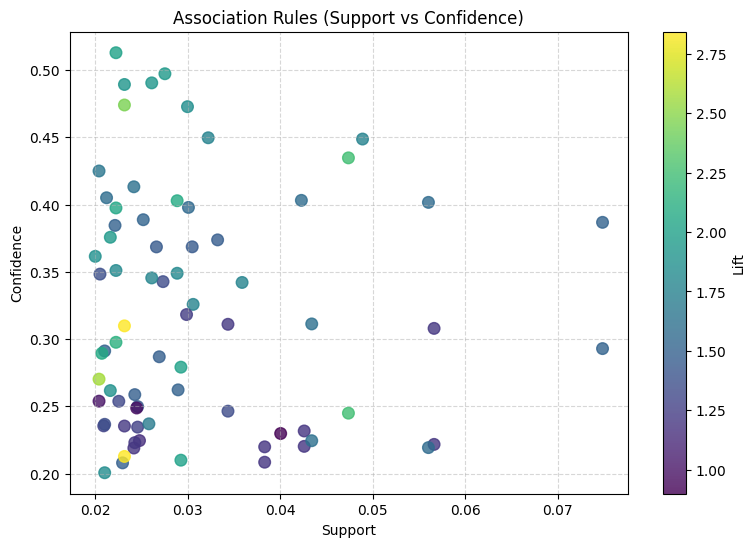

In [14]:
# Apriori

import matplotlib.pyplot as plt
import pandas as pd

# Library wajib untuk Market Basket Analysis / Association Rules
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# 1. READ DATASET TRANSAKSI ONLINE
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-Datasets/master/groceries.csv"

# Karena file groceries berisi daftar item tanpa header, kita baca baris per baris
transactions = []
import urllib.request

req = urllib.request.urlopen(url)
for line in req:
    # Split baris berdasarkan koma dan hapus karakter newline
    item_list = line.decode("utf-8").strip().split(",")
    transactions.append(item_list)

print(f"Total Transaksi: {len(transactions)}")
print("Contoh 3 transaksi pertama:")
for t in transactions[:3]:
    print("-", t)


# 2. PREPROCESSING DATA (ONE-HOT ENCODING TRANSAKSI)
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

print(
    f"\nBentuk Matrix Transaksi (One-Hot): {df_encoded.shape[0]} transaksi x {df_encoded.shape[1]} produk unik"
)


# 3. MENCARI FREQUENT ITEMSETS (ALGORITMA APRIORI)
# min_support = 0.02 (produk/kombinasi harus muncul minimal di 2% dari total transaksi)
frequent_itemsets = apriori(
    df_encoded, min_support=0.02, use_colnames=True, max_len=3
)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)

print("\n--- Top 5 Kombinasi Barang Paling Sering Dibeli (Support) ---")
print(frequent_itemsets.sort_values(by="support", ascending=False).head())


# 4. EKSTRAKSI ASSOCIATION RULES
# Mencari aturan dengan Confidence minimal 0.2 (20%)
rules = association_rules(
    frequent_itemsets, metric="confidence", min_threshold=0.2
)

# Urutkan berdasarkan Lift rasio tertinggi
rules_sorted = rules.sort_values(by="lift", ascending=False)

print("\n--- Top 5 Association Rules Berdasarkan Nilai Lift ---")
print(
    rules_sorted[["antecedents", "consequents", "support", "confidence", "lift"]].head()
)


# 5. VISUALISASI HASIL (SUPPORT VS CONFIDENCE DENGAN COLORBAR LIFT)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    rules["support"],
    rules["confidence"],
    c=rules["lift"],
    cmap="viridis",
    s=70,
    alpha=0.8,
)
plt.colorbar(scatter, label="Lift")
plt.title("Association Rules (Support vs Confidence)")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Total Transaksi: 9835

Total Frequent Itemsets Ditemukan (ECLAT): 123

--- Top 5 Frequent Itemsets (ECLAT) ---
              itemsets   support
25        (whole milk)  0.255516
51  (other vegetables)  0.193493
66        (rolls/buns)  0.183935
80              (soda)  0.174377
7             (yogurt)  0.139502

--- Top 5 Association Rules Berdasarkan Nilai Lift ---
                       antecedents                     consequents   support  \
29               (root vegetables)  (other vegetables, whole milk)  0.023183   
28  (other vegetables, whole milk)               (root vegetables)  0.023183   
19                     (pip fruit)                (tropical fruit)  0.020437   
27   (root vegetables, whole milk)              (other vegetables)  0.023183   
1                   (citrus fruit)                (tropical fruit)  0.019929   

    confidence      lift  
29    0.212687  2.842082  
28    0.309783  2.842082  
19    0.270161  2.574648  
27    0.474012  2.449770  
1     0.240786  2.2

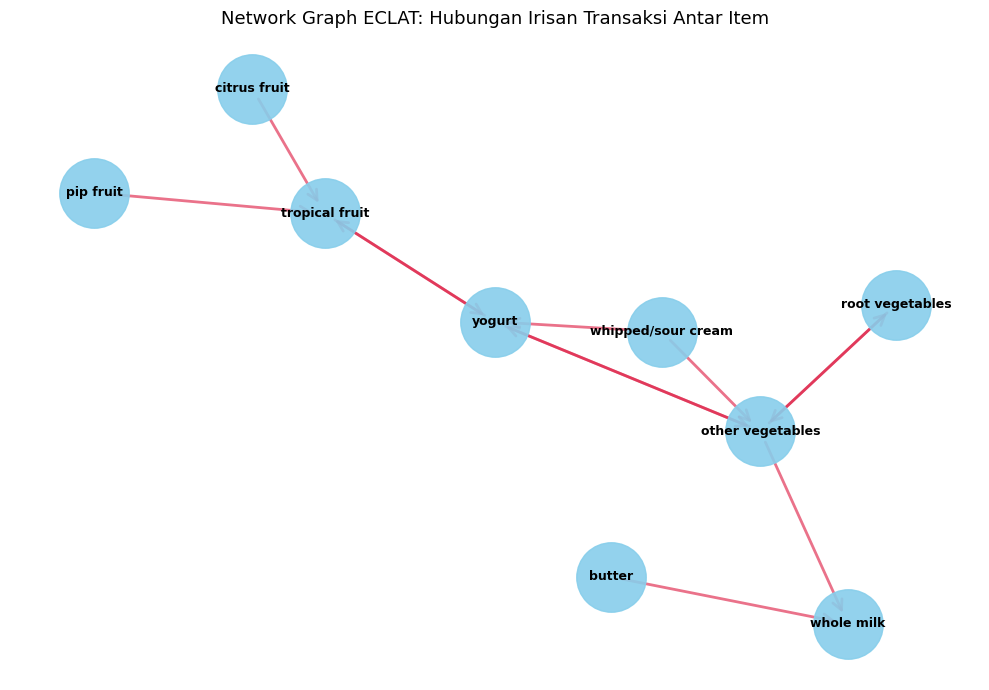

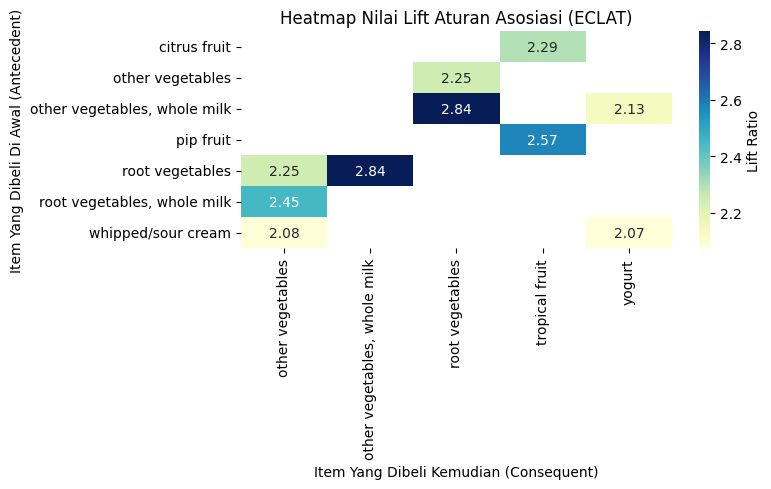

In [15]:
import itertools
import urllib.request
import warnings
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import association_rules

# 1. READ DATASET TRANSAKSI ONLINE
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-Datasets/master/groceries.csv"

transactions = []
req = urllib.request.urlopen(url)
for line in req:
    item_list = line.decode("utf-8").strip().split(",")
    transactions.append(set(item_list))

total_transactions = len(transactions)
print(f"Total Transaksi: {total_transactions}")


# 2. STRUKTUR DATA VERTIKAL UNTUK ECLAT (TID-LIST)
tid_list = {}
for tid, transaction in enumerate(transactions):
    for item in transaction:
        if item not in tid_list:
            tid_list[item] = set()
        tid_list[item].add(tid)


# 3. IMPLEMENTASI ALGORITMA ECLAT (RECURSIVE INTERSECTION)
def eclat(prefix, items, min_support_count, frequent_itemsets):
    for i in range(len(items)):
        item_i, tid_i = items[i]
        support_i = len(tid_i)

        if support_i >= min_support_count:
            new_prefix = prefix + (item_i,)
            frequent_itemsets[new_prefix] = support_i

            # Buat kandidat irisannya (intersection)
            new_items = []
            for j in range(i + 1, len(items)):
                item_j, tid_j = items[j]
                intersection_tid = tid_i.intersection(tid_j)
                if len(intersection_tid) >= min_support_count:
                    new_items.append((item_j, intersection_tid))

            # Rekursi ke tingkat berikutnya
            eclat(new_prefix, new_items, min_support_count, frequent_itemsets)


# Set min_support = 2% (0.02 * total transaksi)
min_support_ratio = 0.02
min_support_count = int(min_support_ratio * total_transactions)

items_sorted = [(item, tids) for item, tids in tid_list.items()]
frequent_itemsets_eclat = {}

# Jalankan ECLAT
eclat((), items_sorted, min_support_count, frequent_itemsets_eclat)

# Ubah ke DataFrame
df_eclat = pd.DataFrame(
    [
        {
            "itemsets": frozenset(itemset),
            "support": count / total_transactions,
        }
        for itemset, count in frequent_itemsets_eclat.items()
    ]
)

print(f"\nTotal Frequent Itemsets Ditemukan (ECLAT): {len(df_eclat)}")
print("\n--- Top 5 Frequent Itemsets (ECLAT) ---")
print(df_eclat.sort_values(by="support", ascending=False).head())


# 4. EKSTRAKSI ASSOCIATION RULES
rules = association_rules(
    df_eclat, metric="confidence", min_threshold=0.2
)
rules_sorted = rules.sort_values(by="lift", ascending=False)

print("\n--- Top 5 Association Rules Berdasarkan Nilai Lift ---")
print(
    rules_sorted[["antecedents", "consequents", "support", "confidence", "lift"]].head()
)


# 5. VISUALISASI 1: NETWORK GRAPH (SANGAT COCOK UNTUK ECLAT)
plt.figure(figsize=(10, 7))

# Ambil 15 aturan terkuat
top_rules = rules_sorted.head(15)

G = nx.DiGraph()
for _, row in top_rules.iterrows():
    ant = list(row["antecedents"])[0]
    cons = list(row["consequents"])[0]
    G.add_edge(ant, cons, weight=row["lift"])

pos = nx.spring_layout(G, k=0.6, seed=42)

nx.draw_networkx_nodes(G, pos, node_size=2500, node_color="skyblue", alpha=0.9)
nx.draw_networkx_labels(
    G, pos, font_size=9, font_weight="bold", font_family="sans-serif"
)
nx.draw_networkx_edges(
    G,
    pos,
    width=2,
    alpha=0.6,
    edge_color="crimson",
    arrowstyle="->",
    arrowsize=18,
)

plt.title(
    "Network Graph ECLAT: Hubungan Irisan Transaksi Antar Item", fontsize=13
)
plt.axis("off")
plt.tight_layout()
plt.show()


# 6. VISUALISASI 2: HEATMAP LIFT VALUE (TOP 10 ATURAN)
top_10 = rules_sorted.head(10).copy()
top_10["antecedent_str"] = top_10["antecedents"].apply(
    lambda x: ", ".join(list(x))
)
top_10["consequent_str"] = top_10["consequents"].apply(
    lambda x: ", ".join(list(x))
)

pivot_table = top_10.pivot(
    index="antecedent_str", columns="consequent_str", values="lift"
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Lift Ratio"},
)
plt.title("Heatmap Nilai Lift Aturan Asosiasi (ECLAT)")
plt.xlabel("Item Yang Dibeli Kemudian (Consequent)")
plt.ylabel("Item Yang Dibeli Di Awal (Antecedent)")
plt.tight_layout()
plt.show()

Total Transaksi: 9835

Total Frequent Itemsets Ditemukan (FP-Growth): 122

--- Top 5 Association Rules Berdasarkan Nilai Lift ---
                       antecedents                     consequents   support  \
55  (other vegetables, whole milk)               (root vegetables)  0.023183   
56               (root vegetables)  (other vegetables, whole milk)  0.023183   
19                     (pip fruit)                (tropical fruit)  0.020437   
54   (root vegetables, whole milk)              (other vegetables)  0.023183   
49              (other vegetables)               (root vegetables)  0.047382   

    confidence      lift  
55    0.309783  2.842082  
56    0.212687  2.842082  
19    0.270161  2.574648  
54    0.474012  2.449770  
49    0.244877  2.246605  


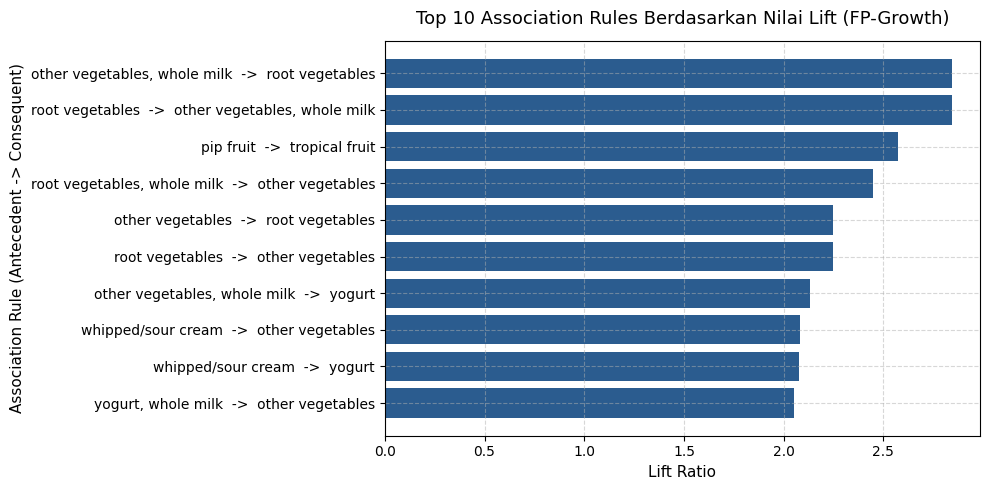

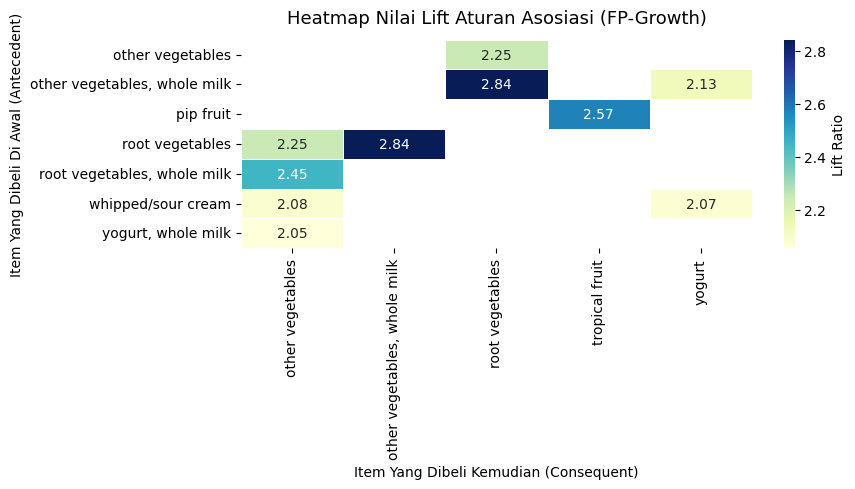

In [16]:
# FP-Growth

import urllib.request
import warnings

# 0. MEMASTIKAN PLOT TAMPIL DI JUPYTER / COLAB & BUNO WARNING
%matplotlib inline
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

# 1. READ DATASET TRANSAKSI ONLINE (groceries.csv)
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-Datasets/master/groceries.csv"

transactions = []
req = urllib.request.urlopen(url)
for line in req:
    item_list = line.decode("utf-8").strip().split(",")
    transactions.append(item_list)

print(f"Total Transaksi: {len(transactions)}")


# 2. PREPROCESSING DATA (ONE-HOT ENCODING)
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)


# 3. TRAINING ALGORITMA FP-GROWTH
# Minimum support = 2% (0.02)
frequent_itemsets_fp = fpgrowth(
    df_encoded, min_support=0.02, use_colnames=True
)

print(f"\nTotal Frequent Itemsets Ditemukan (FP-Growth): {len(frequent_itemsets_fp)}")


# 4. EKSTRAKSI ASSOCIATION RULES
rules = association_rules(
    frequent_itemsets_fp, metric="confidence", min_threshold=0.2
)
rules_sorted = rules.sort_values(by="lift", ascending=False)

print("\n--- Top 5 Association Rules Berdasarkan Nilai Lift ---")
print(
    rules_sorted[["antecedents", "consequents", "support", "confidence", "lift"]].head()
)


# 5. VISUALISASI 1: HORIZONTAL BAR PLOT (TOP 10 LIFT RATIO)
top_10_rules = rules_sorted.head(10).copy()

# Konversi frozenset menjadi string agar mudah ditampilkan di grafik
top_10_rules["rule"] = (
    top_10_rules["antecedents"].apply(lambda x: ", ".join(list(x)))
    + "  ->  "
    + top_10_rules["consequents"].apply(lambda x: ", ".join(list(x)))
)

plt.figure(figsize=(10, 5))
plt.barh(top_10_rules["rule"], top_10_rules["lift"], color="#2b5c8f")
plt.xlabel("Lift Ratio", fontsize=11)
plt.ylabel("Association Rule (Antecedent -> Consequent)", fontsize=11)
plt.title("Top 10 Association Rules Berdasarkan Nilai Lift (FP-Growth)", fontsize=13, pad=12)
plt.gca().invert_yaxis()  # Urutkan dari Lift tertinggi di paling atas
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()  # Memaksa render plot ke layar


# 6. VISUALISASI 2: HEATMAP VALUE LIFT (TOP 10 ATURAN)
top_10 = rules_sorted.head(10).copy()
top_10["antecedent_str"] = top_10["antecedents"].apply(
    lambda x: ", ".join(list(x))
)
top_10["consequent_str"] = top_10["consequents"].apply(
    lambda x: ", ".join(list(x))
)

pivot_table = top_10.pivot_table(
    index="antecedent_str", columns="consequent_str", values="lift", aggfunc="max"
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Lift Ratio"},
    linewidths=0.5,
)
plt.title("Heatmap Nilai Lift Aturan Asosiasi (FP-Growth)", fontsize=13, pad=12)
plt.xlabel("Item Yang Dibeli Kemudian (Consequent)", fontsize=10)
plt.ylabel("Item Yang Dibeli Di Awal (Antecedent)", fontsize=10)
plt.tight_layout()
plt.show()  # Memaksa render plot ke layar